# 2026-06-17 Shared candidate receptors - Venn diagrams

Collapses the candidate phage-receptor sets of the three *Pseudomonas* isolates (9-6-2 / 9-2-1 / 10-10-2) into shared vs. strain-unique receptors, then draws **two** Venn diagrams.

**"Same receptor" =** **>=95% identity AND >=80% mutual coverage** (the coverage gate prevents fusing proteins that only share a small domain).

**Method.** Joint **MMseqs2** `easy-cluster` over all ~542 sequences at once (greedy clustering -> no single-linkage chaining). Each resulting cluster = one receptor; a strain is "present" in a cluster if it contributes >=1 member.

**Two figures (because 9-6-2 and 9-2-1 turn out to be near-identical clones):**
- **Fig 1 (`venn_receptors.png`)** — full 3-way Venn. 9-6-2 and 9-2-1 share *all* receptors, so their two circles coincide (this overlap is the finding, drawn honestly).
- **Fig 2 (`venn_receptors_grouped.png`)** — the two clones merged into one group vs 10-10-2 (cleaner 2-set view).

Inputs from [`../data/processed_genome/`](../data/processed_genome/); outputs -> `output/0617_receptor_similarity/` (Venn PNGs + region/membership CSVs).

In [1]:
import os, re, subprocess, shutil
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn3, venn3_circles

DATA_DIR = Path("../data/processed_genome")
OUT_DIR  = Path("output/0617_receptor_similarity")
OUT_DIR.mkdir(parents=True, exist_ok=True)

STRAINS = {
    "9-6-2":   DATA_DIR / "9-6-2_potential_receptors.fasta",
    "9-2-1":   DATA_DIR / "9-2-1_potential_receptors.fasta",
    "10-10-2": DATA_DIR / "10-10-2_potential_receptors.fasta",
}
MMSEQS = shutil.which("mmseqs") or "/opt/homebrew/bin/mmseqs"

# ---- Tunable parameters: definition of "same receptor" ----------------------
MIN_SEQ_ID = 0.95   # >=95% identity
COVERAGE   = 0.80   # AND >=80% mutual coverage (guards against domain-only matches)
COV_MODE   = 0      # mmseqs coverage mode 0 = coverage of query AND target
print("mmseqs:", MMSEQS)

mmseqs: /opt/homebrew/bin/mmseqs


## 1 - Parse FASTA + build combined sequence set

In [2]:
# ---- 10-line FASTA parser (no biopython needed) -----------------------------
def parse_fasta(path):
    """Return {locus_tag: sequence} for a FASTA file (header = first token)."""
    seqs, header, buf = {}, None, []
    with open(path) as fh:
        for line in fh:
            line = line.rstrip("\n")
            if line.startswith(">"):
                if header is not None: seqs[header] = "".join(buf)
                header, buf = line[1:].split()[0], []
            else:
                buf.append(line)
        if header is not None: seqs[header] = "".join(buf)
    return seqs

def locus_num(sid):
    m = re.search(r"_(\d+)$", sid)
    return int(m.group(1)) if m else -1

# Build one combined FASTA of all sequences + a seq_id -> strain map.
combined_fasta = OUT_DIR / "combined_receptors.fasta"
id2strain, counts = {}, {}
with open(combined_fasta, "w") as out:
    for strain, path in STRAINS.items():
        seqs = parse_fasta(path)
        counts[strain] = len(seqs)
        for sid, seq in seqs.items():
            id2strain[sid] = strain
            out.write(f">{sid}\n{seq}\n")
print("sequences per strain:", counts, "| total:", len(id2strain))

sequences per strain: {'9-6-2': 182, '9-2-1': 182, '10-10-2': 178} | total: 542


## 2 - Joint clustering at >=95% identity / >=80% coverage

In [3]:
# Joint clustering of ALL sequences at once (NOT assembled from pairwise matrices).
# easy-cluster uses greedy set-cover clustering -> avoids the single-linkage chaining
# that connected-components on a 95% graph would suffer from.
clust_prefix = OUT_DIR / "clusterRes"
tmp_dir      = OUT_DIR / "mmseqs_tmp_cluster"
cmd = [MMSEQS, "easy-cluster", str(combined_fasta), str(clust_prefix), str(tmp_dir),
       "--min-seq-id", str(MIN_SEQ_ID), "-c", str(COVERAGE),
       "--cov-mode", str(COV_MODE), "-v", "1"]
print(" ".join(cmd))
subprocess.run(cmd, check=True)
clust = pd.read_csv(f"{clust_prefix}_cluster.tsv", sep="\t", names=["rep","member"])
print(clust.shape[0], "members |", clust["rep"].nunique(), "clusters (= receptors at >=95% id)")
clust.head()

/opt/homebrew/bin/mmseqs easy-cluster output/0617_receptor_similarity/combined_receptors.fasta output/0617_receptor_similarity/clusterRes output/0617_receptor_similarity/mmseqs_tmp_cluster --min-seq-id 0.95 -c 0.8 --cov-mode 0 -v 1


542 members | 199 clusters (= receptors at >=95% id)


,rep,member
0,PICBEH_00009,PICBEH_00009
1,PICBEH_00009,OHPLIO_00009
2,PICBEH_00009,BPBBIK_00009
3,PICBEH_00093,PICBEH_00093
4,PICBEH_00093,OHPLIO_00093


## 3 - Map clusters to strain presence (7 Venn regions)

In [4]:
# Each cluster = one "receptor" at the 95% level. Map cluster -> set of strains present.
clust["strain"] = clust["member"].map(id2strain)
cluster_strains = clust.groupby("rep")["strain"].apply(frozenset)
sig_counts = Counter(cluster_strains)

A, B, C = "9-6-2", "9-2-1", "10-10-2"
def region(*present):
    present = frozenset(present)
    return sum(v for k,v in sig_counts.items() if k == present)

Abc = region(A);       aBc = region(B);       abC = region(C)
ABc = region(A,B);     AbC = region(A,C);     aBC = region(B,C)
ABC = region(A,B,C)
total = Abc+aBc+abC+ABc+AbC+aBC+ABC
print(dict(only_A=Abc, only_B=aBc, only_C=abC, AB=ABc, AC=AbC, BC=aBC, all3=ABC))
print("sum of regions:", total, "== total clusters:", len(cluster_strains))
assert total == len(cluster_strains), "region counts do not sum to cluster count"

{'only_A': 0, 'only_B': 0, 'only_C': 17, 'AB': 21, 'AC': 0, 'BC': 0, 'all3': 161}
sum of regions: 199 == total clusters: 199


## 4 - Figure 1: full 3-way Venn (the two clones coincide)

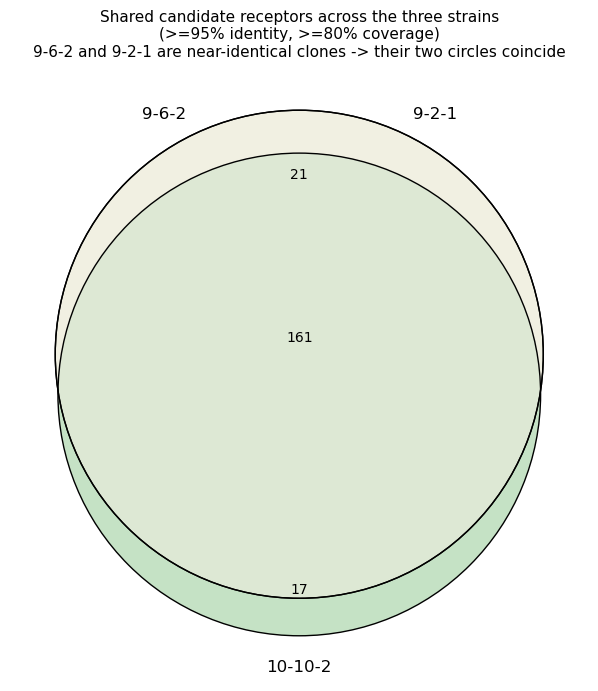

saved output/0617_receptor_similarity/venn_receptors.png


In [5]:
# 9-6-2 and 9-2-1 share every receptor, so their circles coincide and the empty
# regions (only-9-6-2, only-9-2-1, 9-6-2&10-10-2-only, 9-2-1&10-10-2-only) all = 0.
subsets = (Abc, aBc, ABc, abC, AbC, aBC, ABC)
fig, ax = plt.subplots(figsize=(8.5, 8))
v = venn3(subsets=subsets, set_labels=(A, B, C),
          set_colors=("#e8a33d", "#5b9bd5", "#7fbf7f"), alpha=0.45, ax=ax)
venn3_circles(subsets=subsets, ax=ax, linewidth=1)

# Blank the count labels of empty regions so no stray "0" lands in a degenerate spot.
for rid in ["100", "010", "001", "110", "101", "011", "111"]:
    lbl = v.get_label_by_id(rid)
    if lbl is not None and lbl.get_text() == "0":
        lbl.set_text("")

# The 9-6-2 and 9-2-1 set-labels sit on top of each other (coincident circles);
# pull them apart horizontally so both stay readable.
if v.set_labels[0]:
    v.set_labels[0].set_position((-0.30, 0.55)); v.set_labels[0].set_ha("center")
if v.set_labels[1]:
    v.set_labels[1].set_position(( 0.30, 0.55)); v.set_labels[1].set_ha("center")

ax.set_title("Shared candidate receptors across the three strains\n"
             "(>=95% identity, >=80% coverage)\n"
             "9-6-2 and 9-2-1 are near-identical clones -> their two circles coincide",
             fontsize=11)
fig.savefig(OUT_DIR / "venn_receptors.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved", OUT_DIR / "venn_receptors.png")

## 4b - Figure 2: two clones merged into one group vs 10-10-2

{'clone_group_only': 21, 'only_10_10_2': 17, 'shared': 161, 'clone_group_total': 182, 'strain_10_10_2_total': 178}


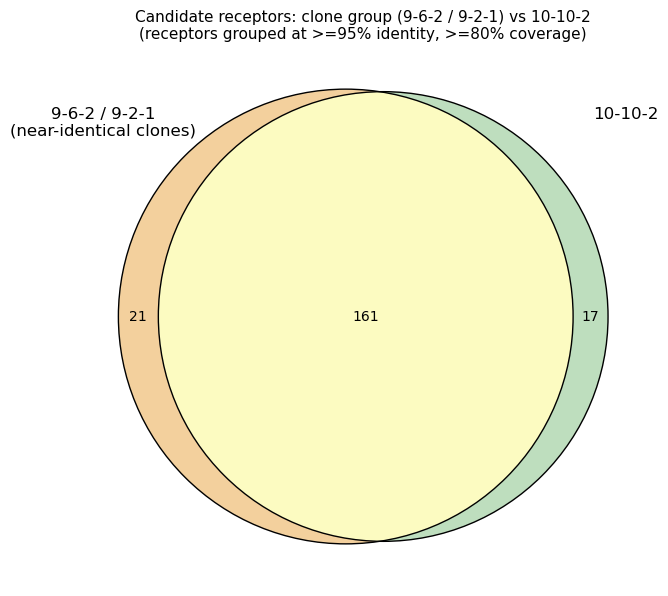

saved output/0617_receptor_similarity/venn_receptors_grouped.png


In [6]:
# Merge the two near-identical clones into one group; compare against 10-10-2.
from matplotlib_venn import venn2, venn2_circles

clone_only = Abc + aBc + ABc   # in 9-6-2 and/or 9-2-1 but NOT 10-10-2   (= 21)
c_only     = abC               # only in 10-10-2                          (= 17)
shared     = AbC + aBC + ABC   # in 10-10-2 AND at least one clone        (= 161)
subsets2 = (clone_only, c_only, shared)
print(dict(clone_group_only=clone_only, only_10_10_2=c_only, shared=shared,
           clone_group_total=clone_only + shared, strain_10_10_2_total=c_only + shared))

fig, ax = plt.subplots(figsize=(8.5, 7))
v2 = venn2(subsets=subsets2,
           set_labels=("9-6-2 / 9-2-1\n(near-identical clones)", "10-10-2"),
           set_colors=("#e8a33d", "#7fbf7f"), alpha=0.5, ax=ax)
venn2_circles(subsets=subsets2, ax=ax, linewidth=1)

# Keep the multi-line left set-label clear of the circle.
if v2.set_labels[0]:
    v2.set_labels[0].set_position((-0.62, 0.50)); v2.set_labels[0].set_ha("center")
if v2.set_labels[1]:
    v2.set_labels[1].set_position(( 0.62, 0.50)); v2.set_labels[1].set_ha("center")

ax.set_title("Candidate receptors: clone group (9-6-2 / 9-2-1) vs 10-10-2\n"
             "(receptors grouped at >=95% identity, >=80% coverage)", fontsize=11)
fig.savefig(OUT_DIR / "venn_receptors_grouped.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved", OUT_DIR / "venn_receptors_grouped.png")

## 5 - Save summary tables

In [7]:
summary = pd.DataFrame({
    "region": ["only 9-6-2","only 9-2-1","only 10-10-2",
               "9-6-2 & 9-2-1","9-6-2 & 10-10-2","9-2-1 & 10-10-2","all three"],
    "n_receptor_clusters": [Abc, aBc, abC, ABc, AbC, aBC, ABC],
})
summary.to_csv(OUT_DIR / "venn_region_counts.csv", index=False)

membership = (cluster_strains.apply(lambda s: "+".join(sorted(s)))
              .rename("strains").reset_index().rename(columns={"rep":"cluster_rep"}))
membership.to_csv(OUT_DIR / "cluster_strain_membership.csv", index=False)
summary

,region,n_receptor_clusters
0,only 9-6-2,0
1,only 9-2-1,0
2,only 10-10-2,17
3,9-6-2 & 9-2-1,21
4,9-6-2 & 10-10-2,0
5,9-2-1 & 10-10-2,0
6,all three,161


## 6 - Sanity check (near-clonal pair)

In [8]:
# Sanity check: 9-6-2 and 9-2-1 are near-clonal -> almost every cluster containing one
# should contain the other.
has_A = cluster_strains.apply(lambda s: A in s)
has_B = cluster_strains.apply(lambda s: B in s)
shared_AB = int((has_A & has_B).sum())
frac = shared_AB / max(int(has_A.sum()), int(has_B.sum()))
print(f"clusters with 9-6-2: {int(has_A.sum())} | with 9-2-1: {int(has_B.sum())} | shared: {shared_AB}")
print(f"9-6-2 / 9-2-1 overlap: {frac:.1%}")
assert frac >= 0.9, "near-clonal 9-6-2/9-2-1 overlap unexpectedly low -- recheck clustering inputs"
print("SANITY CHECK PASSED")

clusters with 9-6-2: 182 | with 9-2-1: 182 | shared: 182
9-6-2 / 9-2-1 overlap: 100.0%
SANITY CHECK PASSED
